# **Assignment 3**
## **Transfer Learning: Reusing a Pretrained ResNet for Image Classification**

In Assignment 2 your CNN learned everything from 50,000 photos, starting from random numbers. Real projects rarely have that much labelled data. **Transfer learning** is the shortcut: take a network already trained on millions of images, keep what it knows (edges, textures, shapes, object parts), and train only what is new.

We test this on the **Oxford-IIIT Pet** dataset (37 breeds of cats and dogs, about 100 photos per breed), using one architecture, a **ResNet-18**, trained in different ways. We ask *when* reusing pretrained knowledge pays off, and *what it costs*.

> **MISSION LOG - Day 3**
>
> Mary's new vision system works, but it needed tens of thousands of labelled photos and a long training run. Out here you have neither. While digging through the lower deck storage for a spare cable, your hand lands on a dusty drive: **"MARY v0, general vision. DO NOT DELETE."** It is a backup of Mary trained on millions of everyday photos long before the mission began. She already knows edges, fur, wheels and wings. She just has no idea what an asteroid is.
>
> **Your job:** decide how much of v0's vision to keep and how much to retrain, and prove it with data. (Practice dataset: 37 breeds of cats and dogs.)
>
> *(Story cells like this one are just for flavour. The technical instructions are always in the Steps.)*

====================================================================================================

### **How this assignment works**

**Part 1 (Steps 1-3): run and observe.** You only run the cells and look at the output. Each Step says what to notice. No decisions yet.

**Part 2 (Steps 4-12): you decide.** From Step 4 on, the notebook asks you for a few short choices (what to freeze, how fast to learn) and a few predictions (*which will win?*). It checks your choices, runs the experiments, and shows whether you were right. You never need to remember syntax. Look for the cells marked `TASK`.

**Before you start**
1) **Save your own copy:** *File → Save a copy in Drive*.
2) **Turn on a GPU:** *Runtime → Change runtime type → T4 GPU → Save*. We train about 20 models, which takes a few tens of minutes on a GPU and hours on a CPU.
3) **The first run downloads the dataset** (about 800 MB). That takes a few minutes, once.
4) **Run the cells in order, from top to bottom.** If a cell shows an error, read the *last line* first.
5) At the end there are **six short written questions**.

**The experiment.** The same ResNet-18, the same data, the same loss, optimizer, epochs and seed. Only the starting weights and *which weights are allowed to change* differ:

| Strategy | Starts from | What gets trained |
|---|---|---|
| **Scratch** | random weights | everything |
| **Frozen** (feature extraction) | ImageNet weights | only the new head |
| **Fine-tune** | ImageNet weights | the new head plus the top block(s), gently |

| Step | What happens |
|---|---|
| 1-2 | Setup and a first look at the Pets data |
| 3 | **Meet MARY v0**: open up the pretrained ResNet-18 |
| 4 | **Design** the strategies: what to freeze, how fast to learn |
| 5-6 | Train and compare the strategies |
| 7 | **Meet your models** on single photos |
| 8-11 | Four experiments: scarce data, learning rate, unfreezing depth, learning-rate schedules |
| 12 | VGG16 vs ResNet-18 |
| 13 | Reflect |

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 1: Setup**
Nothing to fill in. Run the two cells.
- The first imports every library we use: <blue>**torch**</blue> for tensors and layers, <blue>**torchvision**</blue> for the Pets dataset, image preprocessing and the <green>**pretrained models**</green>, <blue>**sklearn**</blue> for accuracy and F1, <blue>**matplotlib**</blue> and <blue>**pandas**</blue> for plots and tables. The random seed makes results repeatable.
- The second defines small helper functions that give feedback on your answers later (✅ or ❌ with an explanation).

In [1]:
# Import necessary libraries
import math
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import models, transforms, datasets
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
from IPython.display import display

my_seed = 42
torch.manual_seed(my_seed)
np.random.seed(my_seed)

# Set device (GPU if available, else CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Running on:", device)

Running on: cuda


In [2]:
# Helpers that give feedback on your answers (nothing to edit)
def require(condition, message):
    '''Stop here (with a helpful message) if the condition is not met.'''
    if not condition:
        raise ValueError(message)

def choose(label, mine, options):
    '''options = {choice: (is_correct, explanation)}. Explains your choice; stops if it is not the right one.'''
    if mine is None:
        raise ValueError(f"{label}: you haven't made a choice yet (it is still None). Options: {list(options)}")
    require(mine in options, f"{label}: pick one of {list(options)}")
    good, why = options[mine]
    print(("✅" if good else "❌"), f"{label} = {mine!r}. {why}")
    require(good, f"{label}: not quite. Read the explanation above, then change your choice and run the cell again.")

def count_params(model):
    '''Total number of learnable numbers (weights and biases) in a model.'''
    return sum(p.numel() for p in model.parameters())

def trainable_params(model):
    '''Only the numbers that are allowed to change during training (requires_grad = True).'''
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 2: The data**
Nothing to fill in. Run the two cells.

**What the cells do**
1) <blue>**The pretrained model has fixed expectations.**</blue> MARY v0 was trained on ImageNet with photos shown at <green>**224 x 224 pixels**</green>, each colour channel normalised with ImageNet's own mean <green>**(0.485, 0.456, 0.406)**</green> and standard deviation <green>**(0.229, 0.224, 0.225)**</green>. Normalising means `(p - mean) / std`, as in Assignment 2, but this time the numbers are fixed by the pretrained filters. To reuse them, we prepare our photos the same way.
2) Pets photos come in all sizes, so each is shrunk to a 256 x 256 square. For **training** we take a random 224 x 224 crop and flip it half of the time (<green>**data augmentation**</green>: a slightly different picture each epoch). For **validation and testing** we always take the centre crop, so measurements are repeatable. To save time, the photos are decoded and shrunk **once** and kept in memory.
3) The dataset has two official parts, <blue>**trainval**</blue> (3,680 photos) and <blue>**test**</blue> (3,669 photos), with <blue>**37 breeds**</blue>. We split trainval into <green>**80% training**</green> and <green>**20% validation**</green>:
   - **training** photos: what the model learns from;
   - **validation** photos: a *practice exam*, used whenever we need to **make a decision** (for example which learning rate is best);
   - **test** photos: the *final exam*, used only to **report** final results. Picking settings by peeking at the test set would make the final number flattering but dishonest.
4) Training uses batches of 32 photos, so the model updates its weights once per 32 photos.

👀 **What to notice:** the batch shape `(32, 3, 224, 224)` (about 49 times more numbers per photo than the 32 x 32 photos of Assignment 2, which is why training takes longer), and how alike some breeds look.

In [3]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Stage 1 (done once per photo): shrink to a 256 x 256 square and keep as integers 0-255
prepare = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(256), transforms.PILToTensor()])

# Stage 2 (every time a photo is used): crop, (flip), scale to 0-1, normalise
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0), antialias=True),
    transforms.RandomHorizontalFlip(),
    transforms.ConvertImageDtype(torch.float32),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.ConvertImageDtype(torch.float32),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Load the Pets dataset (downloads ~800 MB the first time, then decodes and shrinks every photo once)
raw_trainval = datasets.OxfordIIITPet(root='./data', split='trainval', target_types='category', download=True, transform=prepare)
raw_test = datasets.OxfordIIITPet(root='./data', split='test', target_types='category', download=True, transform=prepare)
classes = raw_trainval.classes          # the 37 breed names

def load_into_memory(ds):
    images, labels = [], []
    for x, y in DataLoader(ds, batch_size=64, num_workers=2):
        images.append(x); labels.append(y)
    return torch.cat(images), torch.cat(labels)

X_trainval, y_trainval = load_into_memory(raw_trainval)
X_test, y_test = load_into_memory(raw_test)

class PetsDataset(Dataset):
    '''A view on the in-memory photos: the chosen indices, with a transform applied every time a photo is used.'''
    def __init__(self, images, labels, indices, transform):
        self.images, self.labels, self.indices, self.transform = images, labels, indices, transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = int(self.indices[i])
        return self.transform(self.images[j]), int(self.labels[j])

# Random 80 / 20 split of trainval into training and validation photos
perm = torch.randperm(len(y_trainval), generator=torch.Generator().manual_seed(my_seed))
n_val = int(0.2 * len(perm))
val_idx, train_idx = perm[:n_val], perm[n_val:]

train_dataset = PetsDataset(X_trainval, y_trainval, train_idx, train_transform)
val_dataset = PetsDataset(X_trainval, y_trainval, val_idx, eval_transform)
test_dataset = PetsDataset(X_test, y_test, torch.arange(len(y_test)), eval_transform)

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"Training: {len(train_dataset)} photos | Validation: {len(val_dataset)} | Test: {len(test_dataset)} | Breeds: {len(classes)}")
print(f"One epoch = {len(train_loader)} weight updates (batches of {batch_size})")

100%|██████████| 792M/792M [00:20<00:00, 37.9MB/s]
100%|██████████| 19.2M/19.2M [00:00<00:00, 19.4MB/s]


Training: 2944 photos | Validation: 736 | Test: 3669 | Breeds: 37
One epoch = 92 weight updates (batches of 32)


Batch of images: torch.Size([32, 3, 224, 224])
Batch of labels: torch.Size([32])
Random guessing would be right 1 time in 37 = 2.7%


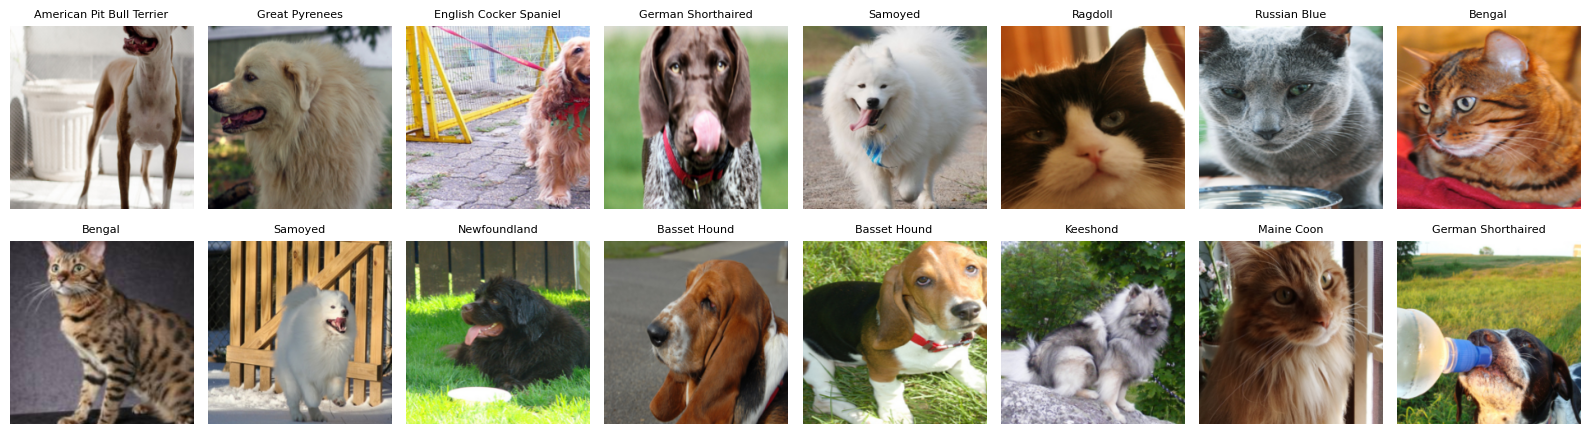

In [4]:
# One batch of photos with their labels
images, labels = next(iter(train_loader))
print("Batch of images:", images.shape)   # (batch size, channels, height, width)
print("Batch of labels:", labels.shape)
print("Random guessing would be right 1 time in", len(classes), f"= {100 / len(classes):.1f}%")

def to_display(img_tensor):
    '''Undo the ImageNet normalisation and reorder axes so matplotlib can show the image.'''
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (img_tensor.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax in axes.flat:
    ax.axis('off')
for ax, img, lab in zip(axes.flat, images, labels):
    ax.imshow(to_display(img))
    ax.set_title(classes[lab], fontsize=8)
plt.tight_layout(); plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 3: Meet MARY v0 (the pretrained ResNet-18)**
Nothing to fill in. Run the three cells and read the output.

`torchvision.models.resnet18` can load a ResNet-18 already trained on <blue>**ImageNet**</blue>: 1.2 million photos in 1000 everyday categories. That is MARY v0. The forward pass is:

`image (3, 224, 224) → conv1 → bn1 → ReLU → maxpool → layer1 → layer2 → layer3 → layer4 → global average pool → fc → 1000 scores`

**What are layer1 to layer4?** They are neither single convolutions nor fully connected layers. Each is a <blue>**stage**</blue>: a stack of <green>**2 residual blocks**</green>, each block holding two 3 x 3 convolutions. A residual block adds two ideas you have not met yet:
1) <blue>**Batch normalisation (bn)**</blue>: after a convolution, the numbers in each channel can drift to very different scales, which makes deep networks hard to train. A batch-norm layer rescales each channel to a steady range and applies a learnable scale and shift. It does not change the shape of the data. It also keeps running averages of what it has seen.
2) <blue>**The shortcut**</blue>: a residual block computes <green>**output = ReLU( F(x) + x )**</green>. `F(x)` is the two convolutions, and `+ x` adds the block's own **input** back onto the result. The block only has to learn a small *correction*, and the `+ x` gives the gradient an easy path backwards, so very deep networks can train. (The last cell of this Step shows this in action.)

Counting the weight layers: 4 stages x 2 blocks x 2 convolutions = 16, plus `conv1`, plus the final `fc` = **18**. That is where the name comes from.

**What each stage does to the shape.** <blue>**layer1**</blue> keeps the size and has <green>**64**</green> channels. In <blue>**layer2, layer3, layer4**</blue> the first block uses <green>**stride 2**</green>, so height and width are <green>**halved**</green> and the channels <green>**double**</green> (<green>**128, 256, 512**</green>). Roughly, the deeper the stage, the more abstract the pattern:

| Stage | What it roughly detects |
|---|---|
| layer1 | edges, colours, simple textures |
| layer2 | corners, simple repeating patterns |
| layer3 | object parts: eyes, ears, fur patterns |
| layer4 | patterns specific to whole categories |

The <blue>**global average pool**</blue> replaces each of the 512 feature maps by its single average, giving 512 numbers whatever the photo size. Everything before `fc` is the <green>**backbone**</green> (it turns a photo into 512 numbers that describe it). `fc` is the <green>**head**</green> (it turns that description into class scores).

👀 **What to notice**
- *Cell 1:* the shape after every stage (it matches the description above), and **where the parameters live**: `layer4` alone holds about 75% of the backbone. Our new 37-breed head is tiny in comparison.
- *Cell 2:* MARY v0 names ImageNet categories, not breeds. Her *vocabulary* does not match ours, but her *vision* is what we want to keep.
- *Cell 3:* a 30-layer network with shortcuts keeps a usable gradient at its first layer; without shortcuts it almost vanishes.

In [5]:
# MARY v0: a ResNet-18 trained on ImageNet
v0_weights = models.ResNet18_Weights.DEFAULT
v0 = models.resnet18(weights=v0_weights).to(device).eval()
imagenet_names = v0_weights.meta["categories"]
print(f"MARY v0: {count_params(v0):,} parameters, can name {len(imagenet_names)} ImageNet categories.\n")

# Run one photo through the real network, stage by stage
stages = [("conv1+bn1+ReLU", nn.Sequential(v0.conv1, v0.bn1, v0.relu)), ("maxpool", v0.maxpool),
          ("layer1", v0.layer1), ("layer2", v0.layer2), ("layer3", v0.layer3), ("layer4", v0.layer4),
          ("global avg pool", v0.avgpool)]
x = torch.zeros(1, 3, 224, 224, device=device)
print(f"{'input photo':<18}(3, 224, 224)")
with torch.no_grad():
    for name, stage in stages:
        x = stage(x)
        print(f"{'after ' + name:<18}{tuple(x.shape[1:])}")
print(f"The head (fc) receives {int(np.prod(x.shape[1:]))} numbers and outputs {len(imagenet_names)} scores.\n")

# Where do the parameters live?
BLOCKS = ["stem", "layer1", "layer2", "layer3", "layer4"]   # pieces of the backbone, from the input side to the output side
def block_of(param_name):
    first = param_name.split(".")[0]
    return "stem" if first in ("conv1", "bn1") else first   # 'layer1' ... 'layer4' or 'fc'

block_params = {}
for name, p in v0.named_parameters():
    block_params[block_of(name)] = block_params.get(block_of(name), 0) + p.numel()
backbone_params = sum(block_params[b] for b in BLOCKS)
table = pd.DataFrame({"parameters": [block_params[b] for b in BLOCKS + ["fc"]]}, index=BLOCKS + ["fc (old 1000-class head)"])
table["share of backbone (%)"] = [round(100 * block_params[b] / backbone_params, 1) for b in BLOCKS] + [None]
display(table)
new_head = nn.Linear(512, len(classes))
print(f"Our new head (512 -> {len(classes)} breeds) has only {count_params(new_head):,} parameters, "
      f"{100 * count_params(new_head) / (backbone_params + count_params(new_head)):.2f}% of the whole network.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 146MB/s]


MARY v0: 11,689,512 parameters, can name 1000 ImageNet categories.

input photo       (3, 224, 224)
after conv1+bn1+ReLU(64, 112, 112)
after maxpool     (64, 56, 56)
after layer1      (64, 56, 56)
after layer2      (128, 28, 28)
after layer3      (256, 14, 14)
after layer4      (512, 7, 7)
after global avg pool(512, 1, 1)
The head (fc) receives 512 numbers and outputs 1000 scores.



,parameters,share of backbone (%)
stem,9536,0.1
layer1,147968,1.3
layer2,525568,4.7
layer3,2099712,18.8
layer4,8393728,75.1
fc (old 1000-class head),513000,NaN


Our new head (512 -> 37 breeds) has only 18,981 parameters, 0.17% of the whole network.


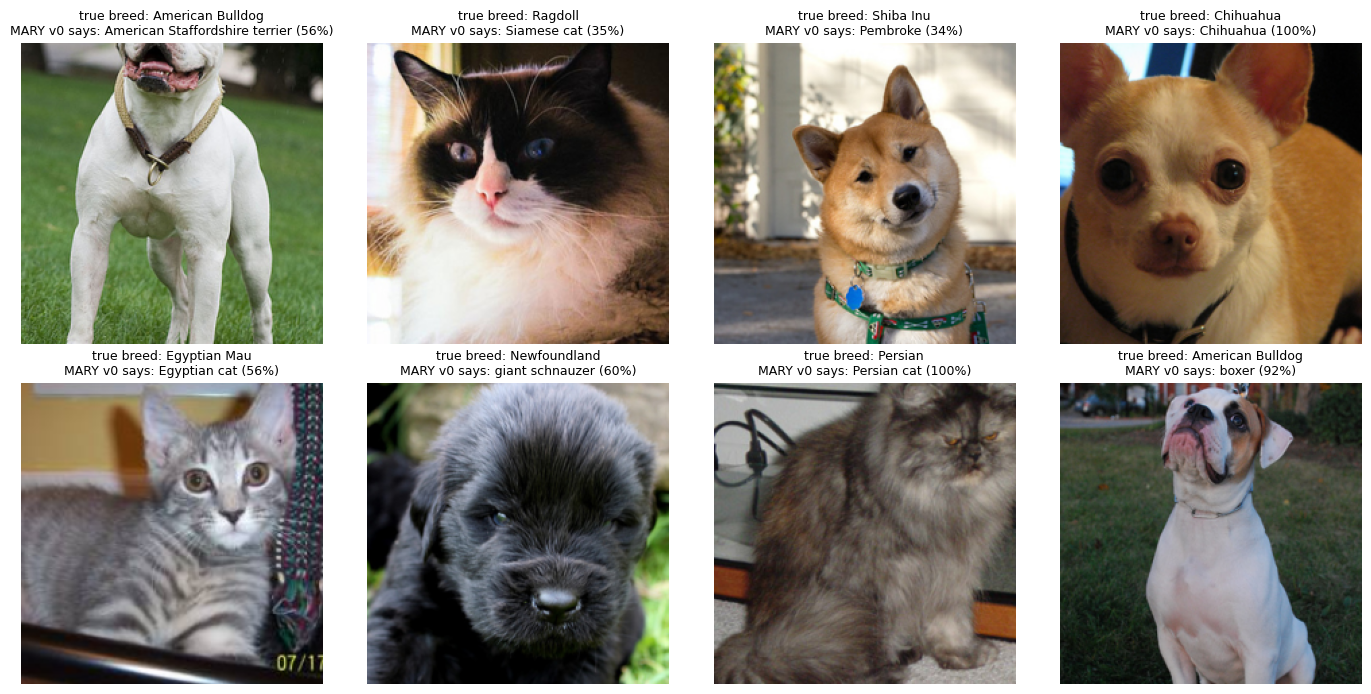

In [6]:
# What does MARY v0 see? She can only name ImageNet's 1000 categories
rng = np.random.RandomState(my_seed)
peek = rng.choice(len(test_dataset), 8, replace=False)
batch = torch.stack([test_dataset[int(i)][0] for i in peek])
with torch.no_grad():
    probs = torch.softmax(v0(batch.to(device)), dim=1).cpu()

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i, img, p in zip(axes.flat, peek, batch, probs):
    top = int(p.argmax())
    ax.imshow(to_display(img)); ax.axis('off')
    ax.set_title(f"true breed: {classes[test_dataset[int(i)][1]]}\nMARY v0 says: {imagenet_names[top]} ({p[top]*100:.0f}%)", fontsize=9)
plt.tight_layout(); plt.show()

In [7]:
# Why shortcuts matter: gradient at the FIRST layer of a 30-layer toy network, with and without the "+ x"
def first_layer_gradient(depth, residual):
    torch.manual_seed(my_seed)
    layers = [nn.Linear(32, 32) for _ in range(depth)]
    h = torch.randn(64, 32)
    for layer in layers:
        out = torch.tanh(layer(h))
        h = h + out if residual else out          # the shortcut: add the input back
    h.pow(2).mean().backward()
    return layers[0].weight.grad.abs().mean().item()

g_plain, g_res = first_layer_gradient(30, False), first_layer_gradient(30, True)
print(f"Gradient at the first layer, 30 layers deep:\n   plain network    : {g_plain:.2e}\n   with shortcuts   : {g_res:.2e}")
print(f"The shortcut version receives a gradient about {g_res / g_plain:.0e} times larger.")

Gradient at the first layer, 30 layers deep:
   plain network    : 1.41e-11
   with shortcuts   : 1.48e-01
The shortcut version receives a gradient about 1e+10 times larger.


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 4: Design the strategies**  *(your first decisions)*
Now we decide *what to freeze*.
1) <blue>**Freezing**</blue> a layer means setting `requires_grad = False` on its parameters. Backpropagation then skips them and the optimizer never changes them. A frozen layer still *runs* in the forward pass: it acts as a fixed feature extractor.
2) <blue>**Early layers are generic, late layers are specific.**</blue> You saw the table in Step 3: edges and textures first, category-specific patterns last. So if we unfreeze anything, we unfreeze from the <green>**top (deepest) down**</green>: the specific layers are the ones that need adapting, and the generic layers are already good.
3) <blue>**The new head is random, the pretrained blocks are already good.**</blue> The head needs big updates. A big update to the pretrained blocks would wreck what they know, so they get a <green>**smaller learning rate**</green> (the size of each nudge). The head's learning rate is <green>**0.001**</green>. You choose how much smaller the backbone's is. We test your choice with real evidence in Step 9.
4) For <green>**Scratch**</green> there is nothing to protect, so every layer trains at the head's rate.

**TASK 4a:** which backbone blocks do you unfreeze for *Fine-tune*?
**TASK 4b:** how should the backbone's learning rate compare with the head's?

In [8]:
# TASK 4a: which backbone blocks do you unfreeze for Fine-tune (besides the new head)?
# Choose one or two names from "stem", "layer1", "layer2", "layer3", "layer4". Remember the table in Step 3: where do most parameters live?
finetune_blocks = ["layer4"] #None

fb = set(finetune_blocks)
require(len(fb) > 0 and fb <= set(BLOCKS), f"Choose one or two names from {BLOCKS}.")
require("layer4" in fb, "❌ Unfreeze from the TOP down: layer4 is the most task-specific block, so it is the first to adapt. Unfreezing earlier blocks while layer4 stays frozen makes no sense.")
require(len(fb) <= 2, "❌ Unfreezing more than two blocks is close to retraining the whole network. Keep it to one or two here (Step 10 tests deeper unfreezing).")
print("✅ Blocks to unfreeze:", sorted(fb))

# TASK 4b: the backbone's learning rate relative to the head's (0.001)?
# 1.0 = the same, 0.1 = ten times smaller, 10.0 = ten times larger
backbone_lr_factor = 0.1 #None
choose("Backbone learning rate factor", backbone_lr_factor, {
    1.0:  (False, "The same rate as the head is too big a nudge for weights that are already good: it can overwrite what MARY v0 knows. We test this in Step 9."),
    0.1:  (True,  "Gentle nudges: the pretrained blocks are adjusted slightly while the random head learns fast. A factor of 0.1 or smaller is the usual choice."),
    10.0: (False, "Ten times larger than the head would be the worst of both worlds: violent changes to weights that were already good."),
})
LR_HEAD = 1e-3
BACKBONE_LR = LR_HEAD * backbone_lr_factor

✅ Blocks to unfreeze: ['layer4']
✅ Backbone learning rate factor = 0.1. Gentle nudges: the pretrained blocks are adjusted slightly while the random head learns fast. A factor of 0.1 or smaller is the usual choice.


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

The next cell turns your decisions into real models. `build_resnet18` loads ImageNet weights (or random ones), swaps in the new 37-way head, and sets `requires_grad` for every parameter. The table shows how much each strategy trains. Nothing to fill in. Just run it.

👀 **What to notice:** Frozen trains only a tiny fraction of the network; Scratch trains all of it.

In [9]:
def build_resnet18(init, trainable_blocks):
    weights = models.ResNet18_Weights.DEFAULT if init == "pretrained" else None
    m = models.resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, len(classes))            # the new head: random, always trainable
    for name, p in m.named_parameters():
        b = block_of(name)
        p.requires_grad = (b == "fc") or (b in trainable_blocks)
    return m.to(device)

STRATEGIES = {
    "Scratch":   {"init": "random",     "blocks": BLOCKS,          "backbone_lr": LR_HEAD},
    "Frozen":    {"init": "pretrained", "blocks": [],              "backbone_lr": BACKBONE_LR},
    "Fine-tune": {"init": "pretrained", "blocks": finetune_blocks, "backbone_lr": BACKBONE_LR},
}

rows = []
for sname, cfg in STRATEGIES.items():
    torch.manual_seed(my_seed)
    m = build_resnet18(cfg["init"], cfg["blocks"])
    rows.append({"Strategy": sname, "Starts from": cfg["init"], "Total parameters": count_params(m),
                 "Trainable parameters": trainable_params(m), "Trainable (%)": round(100 * trainable_params(m) / count_params(m), 2)})
    del m
display(pd.DataFrame(rows).set_index("Strategy"))

,Starts from,Total parameters,Trainable parameters,Trainable (%)
Strategy,,,,
Scratch,random,11195493,11195493,100.00
Frozen,pretrained,11195493,18981,0.17
Fine-tune,pretrained,11195493,8412709,75.14


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 5: Train the strategies**
**The toolkit.** Every model in this assignment is trained and tested by the same functions, defined in the first cell below (nothing to fill in). It is the learning cycle from Assignments 1 and 2, with three additions that transfer learning needs:
1) <blue>**Two learning rates:**</blue> the head (0.001) and the unfrozen backbone blocks (the smaller rate you chose). Frozen parameters are not given to the optimizer at all.
2) <blue>**Frozen means frozen:**</blue> frozen batch-norm layers keep their running averages fixed too.
3) <blue>**Timing and tracking:**</blue> it records the time of every epoch and (if asked) the **validation** accuracy after every epoch. The test set is only touched when we report final results.

**The experiment.** We train **Scratch**, **Frozen** and **Fine-tune**, plus one extra row, **Scratch with 3 times the epochs**, to answer the fair objection "maybe scratch just needs more patience".

**TASK 5:** before running, predict (1) which strategy will have the highest **test accuracy**, and (2) which will have the shortest **time per epoch** (think about what the backward pass has to do in each case).

In [10]:
NUM_EPOCHS = 5   # the same for every strategy

def set_train_mode(model):
    '''Training mode, except that frozen BatchNorm layers keep their running averages fixed.'''
    model.train()
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

def evaluate_model(model, loader):
    '''Return (predicted classes, true classes) for every image in `loader`.'''
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            preds.extend(outputs.argmax(dim=1).cpu().numpy())
            trues.extend(labels.numpy())
    return np.array(preds), np.array(trues)

def accuracy_on(model, loader):
    p, t = evaluate_model(model, loader)
    return accuracy_score(t, p) * 100

def train_model(model, loader, epochs=NUM_EPOCHS, head_lr=LR_HEAD, backbone_lr=BACKBONE_LR, head_prefix="fc.",
                make_scheduler=None, track_loader=None, verbose=True):
    '''Train `model`. Only parameters with requires_grad=True are given to the optimizer.'''
    head, backbone = [], []
    for name, p in model.named_parameters():
        if p.requires_grad:
            (head if name.startswith(head_prefix) else backbone).append(p)
    groups = []
    if head:
        groups.append({"params": head, "lr": head_lr})
    if backbone:
        groups.append({"params": backbone, "lr": backbone_lr})
    optimizer = optim.Adam(groups)
    scheduler = make_scheduler(optimizer) if make_scheduler else None
    criterion = nn.CrossEntropyLoss()
    batch_losses, epoch_times, curve = [], [], []
    for epoch in range(epochs):
        set_train_mode(model)
        t0 = time.time()
        running = 0.0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)   # data and model on the same device
            outputs = model(images)                # 1. guess
            loss = criterion(outputs, labels)      # 2. measure the mistake
            optimizer.zero_grad()                  #    clear old fixes
            loss.backward()                        # 3. work out the fix (backpropagation)
            optimizer.step()                       # 4. nudge the weights
            batch_losses.append(loss.item())
            running += loss.item()
        if device.type == "cuda":
            torch.cuda.synchronize()
        epoch_times.append(time.time() - t0)
        if scheduler is not None:
            scheduler.step()
        if track_loader is not None:
            curve.append(accuracy_on(model, track_loader))
        if verbose:
            extra = f"   validation accuracy: {curve[-1]:.1f}%" if curve else ""
            print(f"Epoch [{epoch+1}/{epochs}]  average loss: {running / len(loader):.4f}  ({epoch_times[-1]:.1f}s){extra}")
    return {"losses": batch_losses, "epoch_times": epoch_times, "curve": curve}

def run_strategy(name, loader=None, epochs=NUM_EPOCHS, track_loader=None, make_scheduler=None, verbose=True, **override):
    '''Build, train and validate one strategy from Step 4 (override lets us change e.g. backbone_lr or blocks).'''
    cfg = {**STRATEGIES[name], **override}
    torch.manual_seed(my_seed)
    model = build_resnet18(cfg["init"], cfg["blocks"])
    out = train_model(model, loader or train_loader, epochs=epochs, backbone_lr=cfg["backbone_lr"],
                      track_loader=track_loader, make_scheduler=make_scheduler, verbose=verbose)
    out.update({"model": model, "trainable": trainable_params(model), "val_acc": accuracy_on(model, val_loader)})
    return out

def smooth(values, window=20):
    '''Moving average so noisy loss curves are readable.'''
    window = max(1, min(window, len(values)))
    return np.convolve(values, np.ones(window) / window, mode='valid')

In [11]:
# TASK 5: your predictions. Choose "Scratch", "Frozen" or "Fine-tune" for each
predicted_best = "Fine-tune" #None             # highest test accuracy
predicted_fastest_epoch = "Frozen" #None       # shortest time per epoch
for p in [predicted_best, predicted_fastest_epoch]:
    require(p in STRATEGIES, 'TASK: choose "Scratch", "Frozen" or "Fine-tune" for both predictions.')
print("Predictions saved:", predicted_best, "/", predicted_fastest_epoch)

results = {}
for sname in STRATEGIES:
    print(f"\n=== {sname} ===")
    results[sname] = run_strategy(sname, track_loader=val_loader)
print(f"\n=== Scratch with {3 * NUM_EPOCHS} epochs (3x) ===")
results["Scratch (3x epochs)"] = run_strategy("Scratch", epochs=3 * NUM_EPOCHS, track_loader=val_loader)

Predictions saved: Fine-tune / Frozen

=== Scratch ===
Epoch [1/5]  average loss: 3.5429  (13.1s)   validation accuracy: 6.4%
Epoch [2/5]  average loss: 3.2362  (11.4s)   validation accuracy: 8.6%
Epoch [3/5]  average loss: 3.0906  (11.2s)   validation accuracy: 13.3%
Epoch [4/5]  average loss: 2.9544  (16.9s)   validation accuracy: 12.5%
Epoch [5/5]  average loss: 2.8768  (13.5s)   validation accuracy: 12.6%

=== Frozen ===
Epoch [1/5]  average loss: 1.8476  (9.7s)   validation accuracy: 83.6%
Epoch [2/5]  average loss: 0.6377  (10.0s)   validation accuracy: 88.7%
Epoch [3/5]  average loss: 0.4264  (8.1s)   validation accuracy: 90.2%
Epoch [4/5]  average loss: 0.3431  (9.1s)   validation accuracy: 89.8%
Epoch [5/5]  average loss: 0.2893  (10.1s)   validation accuracy: 89.8%

=== Fine-tune ===
Epoch [1/5]  average loss: 1.3523  (10.0s)   validation accuracy: 87.1%
Epoch [2/5]  average loss: 0.3401  (9.6s)   validation accuracy: 89.8%
Epoch [3/5]  average loss: 0.1854  (8.5s)   validati

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 6: The head-to-head comparison**
Nothing to fill in. The cell tests every model on the 3,669 **test** photos it has never seen and builds the comparison table:
- <blue>**Test accuracy and F1**</blue> (F1 is computed per breed and then averaged).
- <blue>**Train accuracy**</blue> and the <blue>**train-test gap**</blue>: a big gap means the model is <green>**memorising**</green> the training photos instead of learning something general.
- <blue>**Trainable parameters**</blue> and <blue>**seconds per epoch**</blue>: what each strategy *costs*.

It also checks your predictions from Step 5 and draws the learning curves.

👀 **What to notice:** the accuracy gap between the strategies, whether Scratch with 3x epochs closes it, the train-test gap of each model, and how the learning curves start (where does each strategy begin on epoch 1?).

Strategy,Scratch,Frozen,Fine-tune,Scratch (3x epochs)
Trainable parameters,11195493,18981,8412709,11195493
Test accuracy (%),16.71,88.44,88.39,25.21
F1-score,0.1243,0.8824,0.8808,0.2261
Train accuracy (%),18.65,94.5,99.59,35.05
Train-test gap (points),1.94,6.05,11.2,9.84
Seconds per epoch,13.2,9.4,9.5,11.9


(random guessing would score 2.7%)

Highest accuracy : you said Fine-tune  -> Frozen. Not what you expected? Think about why.
Fastest per epoch: you said Frozen     -> Frozen. 🎯


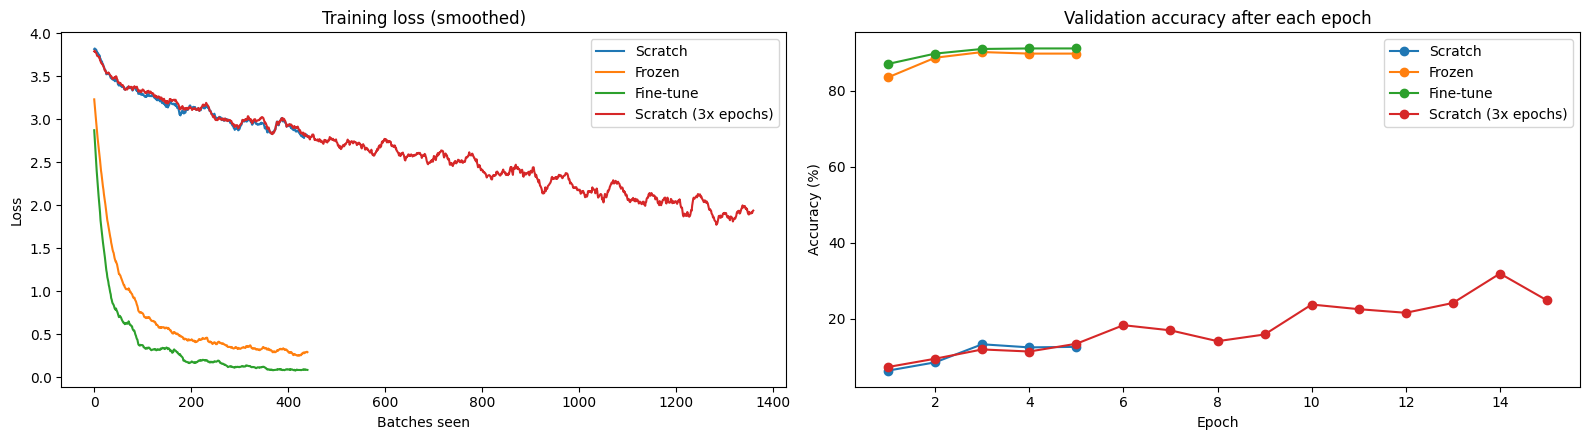

In [12]:
train_eval_loader = DataLoader(PetsDataset(X_trainval, y_trainval, train_idx, eval_transform),
                               batch_size=64, shuffle=False, num_workers=2)   # to measure accuracy on the training photos

rows, test_acc_of = [], {}
for name, r in results.items():
    tp, tt = evaluate_model(r["model"], test_loader)
    test_acc = accuracy_score(tt, tp) * 100
    test_acc_of[name] = test_acc
    train_acc = accuracy_on(r["model"], train_eval_loader)
    rows.append({
        "Strategy": name,
        "Trainable parameters": r["trainable"],
        "Test accuracy (%)": round(test_acc, 2),
        "F1-score": round(f1_score(tt, tp, average='macro', zero_division=0), 4),
        "Train accuracy (%)": round(train_acc, 2),
        "Train-test gap (points)": round(train_acc - test_acc, 2),
        "Seconds per epoch": round(float(np.mean(r["epoch_times"])), 1),
    })
display(pd.DataFrame(rows).set_index("Strategy").astype(object).T)
print(f"(random guessing would score {100 / len(classes):.1f}%)")

# Were your predictions right? (only the three main strategies are candidates)
main = list(STRATEGIES)
actual_best = max(main, key=lambda n: test_acc_of[n])
actual_fastest = min(main, key=lambda n: float(np.mean(results[n]["epoch_times"])))
print(f"\nHighest accuracy : you said {predicted_best:<10} -> {actual_best}. " + ("🎯" if predicted_best == actual_best else "Not what you expected? Think about why."))
print(f"Fastest per epoch: you said {predicted_fastest_epoch:<10} -> {actual_fastest}. " + ("🎯" if predicted_fastest_epoch == actual_fastest else "Hint: which strategy needs no backward pass through the backbone?"))

# Learning curves
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for name, r in results.items():
    axes[0].plot(smooth(r["losses"]), label=name)
    axes[1].plot(range(1, len(r["curve"]) + 1), r["curve"], marker='o', label=name)
axes[0].set_title("Training loss (smoothed)"); axes[0].set_xlabel("Batches seen"); axes[0].set_ylabel("Loss"); axes[0].legend()
axes[1].set_title("Validation accuracy after each epoch"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)"); axes[1].legend()
plt.tight_layout(); plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 7: Meet your models**
Let's see the models on single photos. The first cell picks 10 test photos of 10 different breeds and numbers them 0 to 9 (true breeds hidden). **Look at a photo and decide what *you* think it is.** Then choose a number in the second cell (a dropdown in Colab) and run it: you see each model's top 3 guesses with probabilities, and the true breed. MARY v0 also gives her top guess, in ImageNet's own vocabulary. Run the second cell again with different numbers; a tally counts correct answers.

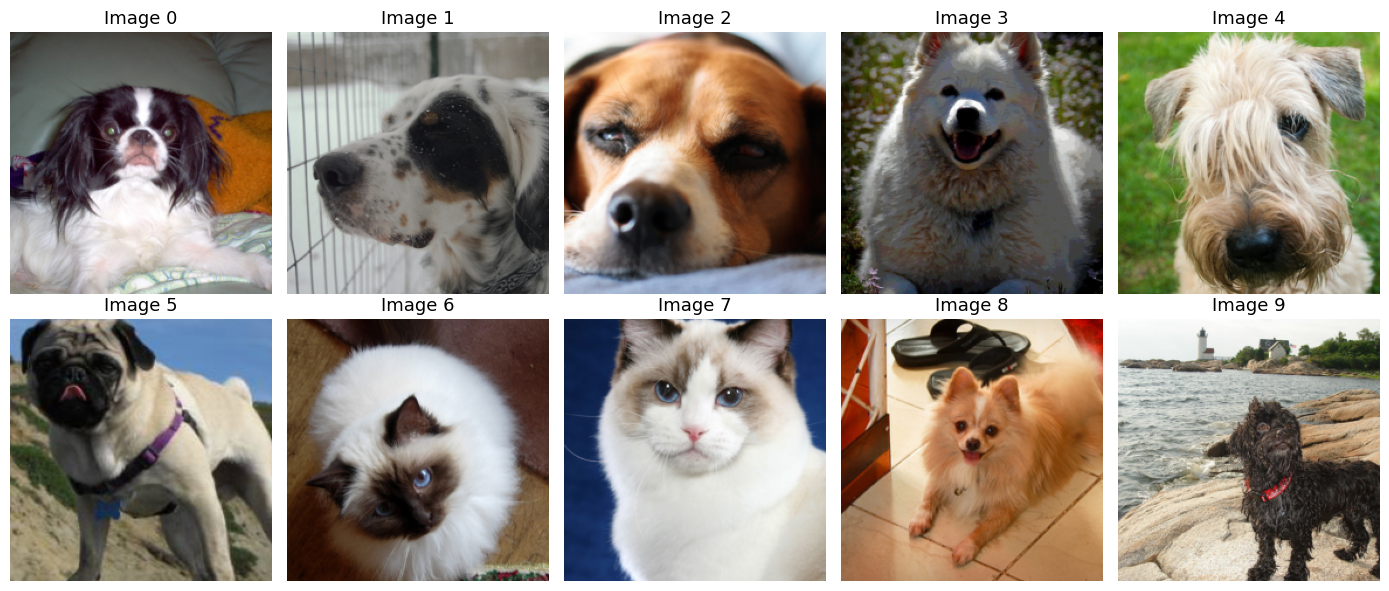

In [13]:
# One random test photo from each of 10 random breeds, in a shuffled order so the number does not give the breed away
targets = y_test.numpy()
rng = np.random.RandomState(my_seed)
demo_classes = rng.choice(len(classes), 10, replace=False)
demo_indices = [int(rng.choice(np.where(targets == c)[0])) for c in demo_classes]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for k, ax in enumerate(axes.flat):
    ax.imshow(to_display(test_dataset[demo_indices[k]][0]))
    ax.set_title(f"Image {k}", fontsize=13)
    ax.axis('off')
plt.tight_layout(); plt.show()

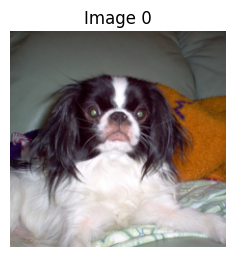

Scratch says: JAPANESE CHIN  (64.6% sure)
     Japanese Chin               64.6%  █████████████████████████
     Saint Bernard               30.2%  ████████████
     Pug                          3.0%  █

Frozen says: JAPANESE CHIN  (99.3% sure)
     Japanese Chin               99.3%  ███████████████████████████████████████
     Havanese                     0.4%  
     Pomeranian                   0.1%  

Fine-tune says: JAPANESE CHIN  (99.8% sure)
     Japanese Chin               99.8%  ███████████████████████████████████████
     Havanese                     0.1%  
     English Setter               0.1%  

MARY v0 (ImageNet vocabulary) says: JAPANESE SPANIEL  (96.4% sure)

True breed: JAPANESE CHIN
Scratch ✅   |   Frozen ✅   |   Fine-tune ✅
Images tried so far: 1  |  Scratch right: 1  |  Frozen right: 1  |  Fine-tune right: 1


In [14]:
# Choose an image (0-9) and run this cell
chosen_image = 0  #@param [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] {type:"raw"}

def predict_text(model, name, x, names, k=3):
    '''Feed ONE image to the model and print its top guesses as text.'''
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x.unsqueeze(0).to(device))[0], dim=0).cpu()
    top = torch.topk(probs, k)
    print(f"{name} says: {names[top.indices[0]].upper()}  ({top.values[0]*100:.1f}% sure)")
    if k > 1:
        for p, idx in zip(top.values, top.indices):
            print(f"     {names[idx]:<26} {p*100:5.1f}%  {'█' * int(p * 40)}")
    return int(top.indices[0])

x, true_label = test_dataset[demo_indices[chosen_image]]
plt.figure(figsize=(2.8, 2.8)); plt.imshow(to_display(x)); plt.axis('off'); plt.title(f"Image {chosen_image}"); plt.show()

guesses = {}
for name in ["Scratch", "Frozen", "Fine-tune"]:
    guesses[name] = predict_text(results[name]["model"], name, x, classes)
    print()
predict_text(v0, "MARY v0 (ImageNet vocabulary)", x, imagenet_names, k=1)

print(f"\nTrue breed: {classes[true_label].upper()}")
print("   |   ".join(f"{n} {'✅' if g == true_label else '❌'}" for n, g in guesses.items()))

if "demo_tally" not in globals():
    demo_tally = {}
demo_tally[chosen_image] = {n: g == true_label for n, g in guesses.items()}
print(f"Images tried so far: {len(demo_tally)}  |  " + "  |  ".join(f"{n} right: {sum(d[n] for d in demo_tally.values())}" for n in guesses))

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 8: What happens when labelled data gets scarce?**
Mary will not have 3,000 labelled photos of asteroids. So we repeat the comparison with only **10% and 25%** of the training photos (the 100% results come from Step 5).

To isolate the effect of *how many different photos* there are, every run gets the **same number of weight updates**: a model that sees 10% of the photos trains for 10 times more epochs (`round(5 / fraction)`: 50 epochs for 10%, 20 for 25%, 5 for 100%). Only the *variety* of the photos changes. The smaller subsets are nested (the 10% subset is inside the 25% subset).

We compare how much of its full-data accuracy each strategy **retains** at 10%: `accuracy at 10% / accuracy at 100%`.

**TASK 8:** before running, predict which strategy **retains the smallest share** of its full-data test accuracy.

👀 **What to notice:** the table and the plot. Which lines stay high and which collapse as the data shrinks?

*(This cell trains 6 models.)*

 10% of the data (294 photos, 50 epochs)  Scratch    test accuracy: 9.8%
 10% of the data (294 photos, 50 epochs)  Frozen     test accuracy: 81.8%
 10% of the data (294 photos, 50 epochs)  Fine-tune  test accuracy: 76.0%
 25% of the data (736 photos, 20 epochs)  Scratch    test accuracy: 14.3%
 25% of the data (736 photos, 20 epochs)  Frozen     test accuracy: 85.9%
 25% of the data (736 photos, 20 epochs)  Fine-tune  test accuracy: 85.0%


,Scratch,Frozen,Fine-tune
Training data,,,
10% (294 photos),9.8,81.8,76.0
25% (736 photos),14.3,85.9,85.0
100% (2944 photos),16.7,88.4,88.4


Share of full-data accuracy kept at 10% of the data: {'Scratch': '59%', 'Frozen': '92%', 'Fine-tune': '86%'}
You predicted Scratch. The smallest share was kept by Scratch. 🎯


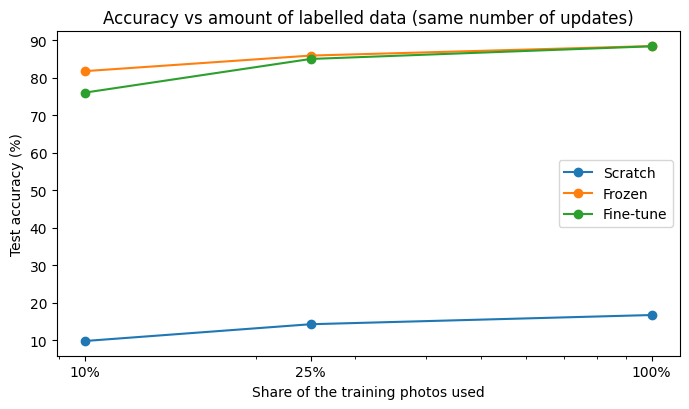

In [15]:
FRACTIONS = [0.1, 0.25]
STRATS = list(STRATEGIES)          # Scratch, Frozen, Fine-tune

# TASK 8: which strategy keeps the smallest share of its full-data accuracy at 10% of the data?
predicted_worst_retention = "Scratch" #None
require(predicted_worst_retention in STRATS, 'TASK: choose "Scratch", "Frozen" or "Fine-tune".')

order = torch.randperm(len(train_idx), generator=torch.Generator().manual_seed(my_seed))   # one fixed order, so subsets are nested

def loader_for_fraction(frac):
    idx = train_idx[order[:int(frac * len(train_idx))]]
    return DataLoader(PetsDataset(X_trainval, y_trainval, idx, train_transform), batch_size=batch_size, shuffle=True, num_workers=2)

sweep = {s: {1.0: test_acc_of[s]} for s in STRATS}      # the 100% runs come from Step 5
for frac in FRACTIONS:
    sub_loader = loader_for_fraction(frac)
    n_img, n_ep = len(sub_loader.dataset), max(1, round(NUM_EPOCHS / frac))
    for s in STRATS:
        r = run_strategy(s, loader=sub_loader, epochs=n_ep, verbose=False)
        sweep[s][frac] = accuracy_on(r["model"], test_loader)
        print(f"{int(frac*100):>3}% of the data ({n_img} photos, {n_ep} epochs)  {s:<10} test accuracy: {sweep[s][frac]:.1f}%")
        del r
        if device.type == "cuda":
            torch.cuda.empty_cache()

all_fracs = FRACTIONS + [1.0]
df_sweep = pd.DataFrame({s: [round(sweep[s][f], 1) for f in all_fracs] for s in STRATS},
                        index=[f"{int(f*100)}% ({int(f*len(train_idx))} photos)" for f in all_fracs])
df_sweep.index.name = "Training data"
display(df_sweep)

retention = {s: sweep[s][0.1] / sweep[s][1.0] * 100 for s in STRATS}
print("Share of full-data accuracy kept at 10% of the data:", {s: f"{v:.0f}%" for s, v in retention.items()})
actual_worst_retention = min(retention, key=retention.get)
print(f"You predicted {predicted_worst_retention}. The smallest share was kept by {actual_worst_retention}. " +
      ("🎯" if predicted_worst_retention == actual_worst_retention else "Not what you expected? Look at the table and think about why."))

plt.figure(figsize=(7, 4.2))
for s in STRATS:
    plt.plot([f * 100 for f in all_fracs], [sweep[s][f] for f in all_fracs], marker='o', label=s)
plt.xscale('log'); plt.xticks([f * 100 for f in all_fracs], [f"{int(f*100)}%" for f in all_fracs])
plt.xlabel("Share of the training photos used"); plt.ylabel("Test accuracy (%)"); plt.title("Accuracy vs amount of labelled data (same number of updates)")
plt.legend(); plt.tight_layout(); plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 9: Why must fine-tuning be gentle?**
In Step 4 you chose how much smaller the backbone's learning rate should be. Let's test it. We fine-tune the same blocks with four backbone learning rates (the head always uses 0.001) and measure the **validation** accuracy. This is a *decision*, so we use the validation set, not the test set. The dashed line shows the **Frozen** model's validation accuracy: a fine-tuned model that scores *below* it has been damaged by its own training.

**TASK 9:** before running, predict which backbone learning rate gives the highest validation accuracy.

👀 **What to notice:** what happens at the largest rate, compared with the Frozen reference line.

*(This cell trains 4 models.)*

backbone lr 0.01: validation accuracy 79.1%
backbone lr 0.001: validation accuracy 82.7%
backbone lr 0.0001: validation accuracy 90.6%
backbone lr 1e-05: validation accuracy 92.0%


,Final training loss,Validation accuracy (%)
Backbone learning rate,,
0.01000,0.422,79.08
0.00100,0.213,82.74
0.00010,0.077,90.62
0.00001,0.254,91.98


Reference: Frozen model validation accuracy = 89.8%
You predicted 0.0001. The best backbone learning rate was 1e-05. Not quite. Compare the rows, especially the largest rate.
The rate you chose in Step 4 was 0.0001.


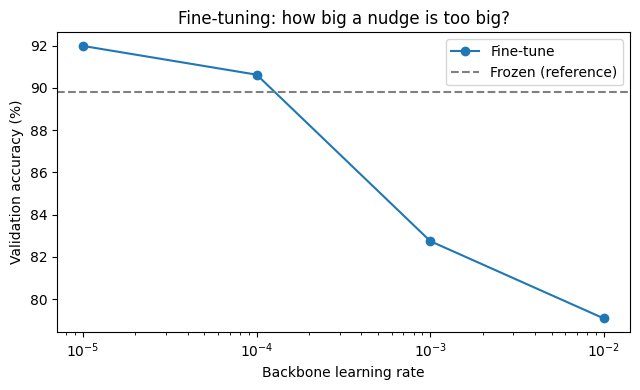

In [16]:
lr_options = [1e-2, 1e-3, 1e-4, 1e-5]
predicted_best_lr = 1e-4 #None     # TASK 9: choose one of the learning rates in the list above
require(predicted_best_lr in lr_options, f"TASK: choose one of {lr_options}")

lr_rows = []
for lr in lr_options:
    r = run_strategy("Fine-tune", backbone_lr=lr, verbose=False)
    lr_rows.append({"Backbone learning rate": lr, "Final training loss": round(float(np.mean(r["losses"][-len(train_loader):])), 3),
                    "Validation accuracy (%)": round(r["val_acc"], 2)})
    print(f"backbone lr {lr:g}: validation accuracy {r['val_acc']:.1f}%")
    del r
    if device.type == "cuda":
        torch.cuda.empty_cache()

df_lr = pd.DataFrame(lr_rows).set_index("Backbone learning rate")
frozen_val = results["Frozen"]["val_acc"]
display(df_lr)
print(f"Reference: Frozen model validation accuracy = {frozen_val:.1f}%")
best_lr = df_lr["Validation accuracy (%)"].idxmax()
print(f"You predicted {predicted_best_lr:g}. The best backbone learning rate was {best_lr:g}. " +
      ("🎯" if predicted_best_lr == best_lr else "Not quite. Compare the rows, especially the largest rate."))
print(f"The rate you chose in Step 4 was {BACKBONE_LR:g}.")

plt.figure(figsize=(6.5, 4))
plt.plot(df_lr.index, df_lr["Validation accuracy (%)"], marker='o', label="Fine-tune")
plt.axhline(frozen_val, color='gray', linestyle='--', label="Frozen (reference)")
plt.xscale('log'); plt.xlabel("Backbone learning rate"); plt.ylabel("Validation accuracy (%)")
plt.title("Fine-tuning: how big a nudge is too big?"); plt.legend(); plt.tight_layout(); plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 10: How deep should we unfreeze?**
In Step 4 you unfroze one or two blocks. What if we unfreeze more? More unfrozen blocks means more power to adapt, but also more trainable parameters, more time per epoch, and more risk of overfitting a small dataset. We train four versions of Fine-tune, from "head only" to "all blocks", and measure the **validation** accuracy.

**TASK 10:** before running, predict which depth gives the highest validation accuracy.

👀 **What to notice:** how accuracy changes as trainable parameters and seconds per epoch grow. Where do the extra parameters stop paying off?

*(This cell trains 4 models.)*

head only   validation accuracy 90.4%
layer4      validation accuracy 90.6%
layer3-4    validation accuracy 90.1%
all blocks  validation accuracy 90.5%


,Trainable parameters,Validation accuracy (%),Seconds per epoch
Unfrozen,,,
head only,18981,90.35,9.3
layer4,8412709,90.62,9.3
layer3-4,10512421,90.08,9.9
all blocks,11195493,90.49,11.8


You predicted layer3-4. The best depth here was layer4. Look at the table: what do the extra parameters buy?


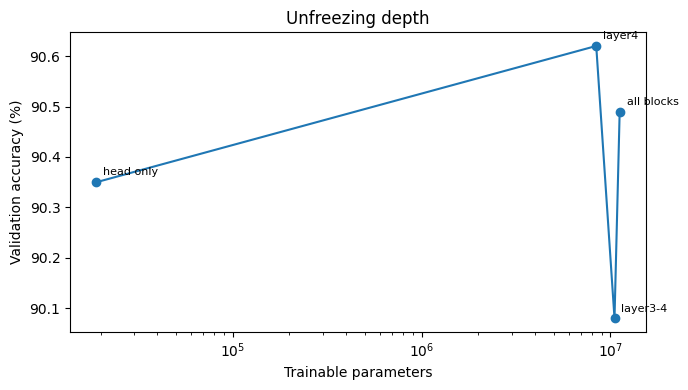

In [17]:
DEPTH_CONFIGS = {"head only": [], "layer4": ["layer4"], "layer3-4": ["layer3", "layer4"], "all blocks": BLOCKS}
predicted_best_depth = "layer3-4" #None    # TASK 10: choose one of the names above
require(predicted_best_depth in DEPTH_CONFIGS, f"TASK: choose one of {list(DEPTH_CONFIGS)}")

depth_rows = []
for dname, blocks in DEPTH_CONFIGS.items():
    r = run_strategy("Fine-tune", blocks=blocks, verbose=False)
    depth_rows.append({"Unfrozen": dname, "Trainable parameters": r["trainable"], "Validation accuracy (%)": round(r["val_acc"], 2),
                       "Seconds per epoch": round(float(np.mean(r["epoch_times"])), 1)})
    print(f"{dname:<11} validation accuracy {r['val_acc']:.1f}%")
    del r
    if device.type == "cuda":
        torch.cuda.empty_cache()

df_depth = pd.DataFrame(depth_rows).set_index("Unfrozen")
display(df_depth)
best_depth = df_depth["Validation accuracy (%)"].idxmax()
print(f"You predicted {predicted_best_depth}. The best depth here was {best_depth}. " + ("🎯" if predicted_best_depth == best_depth else "Look at the table: what do the extra parameters buy?"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(df_depth["Trainable parameters"], df_depth["Validation accuracy (%)"], marker='o')
for name, row in df_depth.iterrows():
    ax.annotate(name, (row["Trainable parameters"], row["Validation accuracy (%)"]), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set_xscale('log'); ax.set_xlabel("Trainable parameters"); ax.set_ylabel("Validation accuracy (%)"); ax.set_title("Unfreezing depth")
plt.tight_layout(); plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 11: Learning-rate schedules**
A fixed learning rate is a compromise: big steps make fast early progress but keep the weights jumping around near the end, while small steps are precise but slow. A <blue>**scheduler**</blue> lowers the learning rate during training. After every epoch it updates the rate of both the head and the backbone. Two common schedules:
- <blue>**StepLR**</blue>: multiply the rate by a factor (here 0.1) every 2 epochs.
- <blue>**CosineAnnealingLR**</blue>: follow half a cosine wave from the starting rate down to 0 over all the epochs.

The first cell draws what each schedule does to the rate. The second trains Fine-tune with each of the three (constant, step, cosine) and tracks the validation accuracy. Nothing to fill in. Just run them.

👀 **What to notice:** the three rate curves, and whether the differences in accuracy are large or small for a short run like ours.

*(The second cell trains 3 models.)*

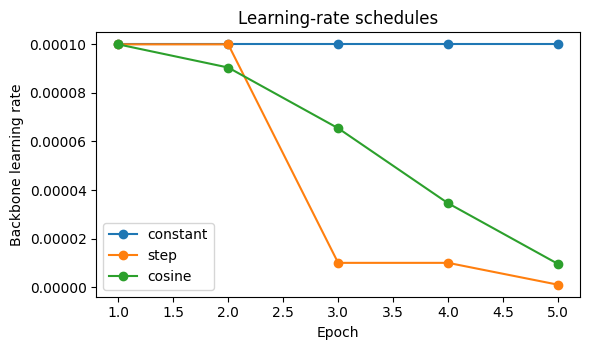

In [18]:
SCHEDULES = {
    "constant": None,
    "step":   lambda o: lr_scheduler.StepLR(o, step_size=2, gamma=0.1),
    "cosine": lambda o: lr_scheduler.CosineAnnealingLR(o, T_max=NUM_EPOCHS),
}

# Draw the learning rate of each schedule, epoch by epoch (using a dummy parameter)
dummy = nn.Parameter(torch.zeros(1))
plt.figure(figsize=(6, 3.6))
for sname, make in SCHEDULES.items():
    opt = optim.SGD([dummy], lr=BACKBONE_LR)
    sch = make(opt) if make else None
    lrs = []
    for e in range(NUM_EPOCHS):
        lrs.append(opt.param_groups[0]["lr"]); opt.step()
        if sch: sch.step()
    plt.plot(range(1, NUM_EPOCHS + 1), lrs, marker='o', label=sname)
plt.xlabel("Epoch"); plt.ylabel("Backbone learning rate"); plt.title("Learning-rate schedules"); plt.legend(); plt.tight_layout(); plt.show()


=== Fine-tune with a constant learning rate ===
Epoch [1/5]  average loss: 1.3523  (9.8s)   validation accuracy: 87.1%
Epoch [2/5]  average loss: 0.3401  (9.9s)   validation accuracy: 89.8%
Epoch [3/5]  average loss: 0.1854  (9.9s)   validation accuracy: 91.0%
Epoch [4/5]  average loss: 0.1191  (8.5s)   validation accuracy: 91.2%
Epoch [5/5]  average loss: 0.0841  (9.2s)   validation accuracy: 91.2%

=== Fine-tune with a step learning rate ===
Epoch [1/5]  average loss: 1.3523  (9.9s)   validation accuracy: 87.1%
Epoch [2/5]  average loss: 0.3401  (10.0s)   validation accuracy: 89.8%
Epoch [3/5]  average loss: 0.1859  (10.0s)   validation accuracy: 91.6%
Epoch [4/5]  average loss: 0.1651  (8.6s)   validation accuracy: 91.4%
Epoch [5/5]  average loss: 0.1576  (8.7s)   validation accuracy: 91.4%

=== Fine-tune with a cosine learning rate ===
Epoch [1/5]  average loss: 1.3523  (9.9s)   validation accuracy: 87.1%
Epoch [2/5]  average loss: 0.3398  (9.8s)   validation accuracy: 90.4%
Epoch

,Validation accuracy (%),Final training loss
constant,91.17,0.084
step,91.44,0.158
cosine,91.98,0.103


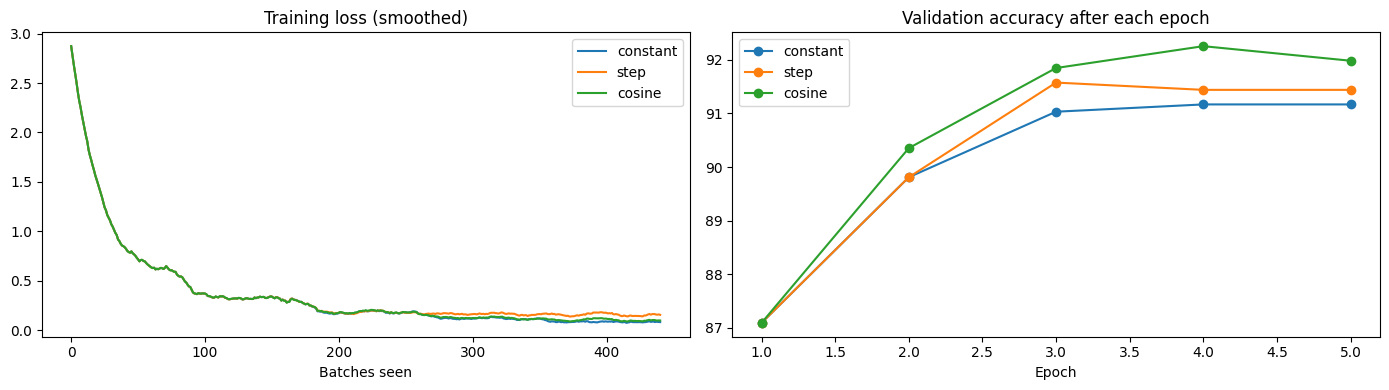

In [19]:
sched_results = {}
for sname, make in SCHEDULES.items():
    print(f"\n=== Fine-tune with a {sname} learning rate ===")
    sched_results[sname] = run_strategy("Fine-tune", make_scheduler=make, track_loader=val_loader)

df_sched = pd.DataFrame({"Validation accuracy (%)": {n: round(r["val_acc"], 2) for n, r in sched_results.items()},
                         "Final training loss": {n: round(float(np.mean(r["losses"][-len(train_loader):])), 3) for n, r in sched_results.items()}})
display(df_sched)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for n, r in sched_results.items():
    axes[0].plot(smooth(r["losses"]), label=n)
    axes[1].plot(range(1, NUM_EPOCHS + 1), r["curve"], marker='o', label=n)
axes[0].set_title("Training loss (smoothed)"); axes[0].set_xlabel("Batches seen"); axes[0].legend()
axes[1].set_title("Validation accuracy after each epoch"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 12: VGG16 vs ResNet-18**
The Section 3 resources mention another famous backbone, <blue>**VGG16**</blue>. It has no shortcuts and no batch-norm: 13 convolutions (all 3 x 3) in 5 groups, each group ending with a 2 x 2 max-pool, then **three fully connected layers**:

`image (3, 224, 224) → [13 convs + 5 max-pools] → (512, 7, 7) → flatten (25,088 numbers) → Linear(25088, 4096) → ReLU → Linear(4096, 4096) → ReLU → Linear(4096, 1000)`

Unlike ResNet, VGG flattens the final feature maps directly (no global average pool). To transfer it, we replace its **last** layer (4096 → 37) and freeze everything else, which makes it the direct counterpart of ResNet's *Frozen* strategy.

The first cell prints how big VGG16 is next to ResNet-18. Then, **TASK 12:** predict which frozen backbone gets the higher test accuracy: `"VGG16"`, `"ResNet-18"`, or `"similar"` (within 2 points). The second cell trains VGG16 Frozen and compares.

👀 **What to notice:** the total size of VGG16 compared with ResNet-18, and whether more parameters bought more accuracy.

In [20]:
vgg_weights = models.VGG16_Weights.DEFAULT
vgg = models.vgg16(weights=vgg_weights).to(device).eval()
with torch.no_grad():
    flat = int(np.prod(vgg.features(torch.zeros(1, 3, 224, 224, device=device)).shape[1:]))
print(f"VGG16 flatten size: {flat:,} numbers  (ResNet-18's head receives only 512)")
print(f"VGG16 first fully connected layer: {count_params(vgg.classifier[0]):,} parameters")
print(f"VGG16 total: {count_params(vgg):,} parameters  |  ResNet-18 total: {count_params(v0):,}  ->  VGG16 is {count_params(vgg) / count_params(v0):.0f} times bigger")
del vgg

# TASK 12: which frozen backbone gets the higher test accuracy?
predicted_vgg = "ResNet-18" #None     # "VGG16", "ResNet-18" or "similar"
require(predicted_vgg in ["VGG16", "ResNet-18", "similar"], 'TASK: choose "VGG16", "ResNet-18" or "similar".')

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:13<00:00, 40.3MB/s]


VGG16 flatten size: 25,088 numbers  (ResNet-18's head receives only 512)
VGG16 first fully connected layer: 102,764,544 parameters
VGG16 total: 138,357,544 parameters  |  ResNet-18 total: 11,689,512  ->  VGG16 is 12 times bigger


In [21]:
def build_vgg16_frozen():
    m = models.vgg16(weights=vgg_weights)
    m.classifier[6] = nn.Linear(4096, len(classes))                 # the new head
    for name, p in m.named_parameters():
        p.requires_grad = name.startswith("classifier.6")           # everything else is frozen
    return m.to(device)

torch.manual_seed(my_seed)
vgg_model = build_vgg16_frozen()
print(f"VGG16 Frozen: {count_params(vgg_model):,} parameters, {trainable_params(vgg_model):,} trainable")
vgg_run = train_model(vgg_model, train_loader, epochs=NUM_EPOCHS, head_prefix="classifier.6.")
vgg_acc = accuracy_on(vgg_model, test_loader)
res_acc = test_acc_of["Frozen"]

display(pd.DataFrame([
    {"Model": "ResNet-18 Frozen", "Total parameters": count_params(results["Frozen"]["model"]), "Trainable parameters": results["Frozen"]["trainable"],
     "Test accuracy (%)": round(res_acc, 2), "Seconds per epoch": round(float(np.mean(results["Frozen"]["epoch_times"])), 1)},
    {"Model": "VGG16 Frozen", "Total parameters": count_params(vgg_model), "Trainable parameters": trainable_params(vgg_model),
     "Test accuracy (%)": round(vgg_acc, 2), "Seconds per epoch": round(float(np.mean(vgg_run["epoch_times"])), 1)},
]).set_index("Model"))

actual_vgg = "similar" if abs(vgg_acc - res_acc) <= 2 else ("VGG16" if vgg_acc > res_acc else "ResNet-18")
print(f"You predicted {predicted_vgg}. Result: {actual_vgg} (VGG16 {vgg_acc:.1f}% vs ResNet-18 {res_acc:.1f}%). " + ("🎯" if predicted_vgg == actual_vgg else "Not what you expected? Compare the sizes too."))
del vgg_model
if device.type == "cuda":
    torch.cuda.empty_cache()

VGG16 Frozen: 134,412,133 parameters, 151,589 trainable
Epoch [1/5]  average loss: 0.8417  (18.3s)
Epoch [2/5]  average loss: 0.3161  (19.9s)
Epoch [3/5]  average loss: 0.2364  (17.4s)
Epoch [4/5]  average loss: 0.2367  (16.9s)
Epoch [5/5]  average loss: 0.1930  (17.7s)


,Total parameters,Trainable parameters,Test accuracy (%),Seconds per epoch
Model,,,,
ResNet-18 Frozen,11195493,18981,88.44,9.4
VGG16 Frozen,134412133,151589,90.05,18.1


You predicted ResNet-18. Result: similar (VGG16 90.1% vs ResNet-18 88.4%). Not what you expected? Compare the sizes too.


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 13: Reflect**

Answer these in the text cell below, in your own words. Two or three sentences each is enough. "Pretrained is better" is not an answer: say *what* you see in *your* tables and plots.

**Q1.** (Steps 5-6) Which strategy was most accurate and which least, and by how many points? Did giving Scratch three times the epochs close the gap? What does that say about starting weights versus training time?

**Q2.** (Steps 3, 6) The backbone hands the head 512 numbers per photo. Why does that make it possible to reuse the same backbone for a completely different set of classes? Compare Frozen and Fine-tune on accuracy, trainable parameters and time per epoch: when would you pick each?

**Q3.** (Step 8) How did each strategy behave as the amount of data shrank? Why does a pretrained backbone help most when labelled data is scarce?

**Q4.** (Step 9) What happened at the largest backbone learning rate, and why? Use the words "pretrained knowledge" in your answer.

**Q5.** (Steps 10-11) Based on your tables, how many blocks would you unfreeze, and would you use a learning-rate schedule? Justify with numbers, not just accuracy (think parameters and time too).

**Q6.** (Steps 3, 12) In Step 3, why did the network *with* shortcuts keep a larger gradient at its first layer? In Step 12, did VGG16's many extra parameters buy extra accuracy compared with ResNet-18?

**Your answers:**

**Q1:**

Frozen achieved the highest test accuracy of 88.44%, while Scratch achieved the lowest at 16.71%, a difference of 71.73 percentage points. Training Scratch for 15 epochs improved its accuracy to 25.21%, but it still remained 63.23 points behind Frozen. This shows that pretrained weights provide a much greater advantage than simply increasing training time when labelled data is limited.


**Q2:**

The backbone extracts 512 general visual features from each image, which can be reused for different classification tasks by replacing the final classification head. Frozen achieved 88.44% test accuracy with only 18,981 trainable parameters and 9.4 seconds per epoch, while Fine-tune achieved 88.39% with 8,412,709 trainable parameters and 9.5 seconds per epoch. I would choose Frozen for efficiency and limited data, and Fine-tune when the new task requires adapting pretrained features and validation results justify the additional parameters.


**Q3:**

At 10% training data, Scratch accuracy dropped to 9.8%, retaining only 59% of its full-data accuracy, while Frozen achieved 81.8% (92% retention) and Fine-tune achieved 76.0% (86% retention). Frozen performed best with limited data because its pretrained backbone already contained useful features such as edges, textures, and object shapes. Scratch had to learn these features from only 294 images, making generalization much more difficult.


**Q4:**

At the largest backbone learning rate of 0.01, validation accuracy dropped to 79.08%, compared with 91.98% at the smallest learning rate of 0.00001. Large parameter updates can overwrite useful pretrained knowledge, reducing the model's ability to generalize. A smaller learning rate preserves pretrained knowledge while allowing gradual adaptation to the new dataset.


**Q5:**

I would unfreeze only layer4 because it achieved the highest validation accuracy of 90.62% with 8,412,709 trainable parameters and 9.3 seconds per epoch, while unfreezing all blocks achieved only 90.49% and required 11.8 seconds per epoch. I would use cosine annealing because it achieved the highest final validation accuracy of 91.98%, compared with 91.44% for StepLR and 91.17% for a constant learning rate. This provides a good balance between accuracy, computational cost, and gradual learning-rate reduction.


**Q6:**

I would unfreeze only layer4 because it achieved the highest validation accuracy of 90.62% with 8,412,709 trainable parameters and 9.3 seconds per epoch, while unfreezing all blocks achieved only 90.49% and required 11.8 seconds per epoch. I would use cosine annealing because it achieved the highest final validation accuracy of 91.98%, compared with 91.44% for StepLR and 91.17% for a constant learning rate. This provides a good balance between accuracy, computational cost, and gradual learning-rate reduction.



In [24]:
# Mission status
print(f"MARY v0 reborn: Fine-tune reads {test_acc_of['Fine-tune']:.1f}% of the pets correctly, Frozen {test_acc_of['Frozen']:.1f}%, "
      f"against {test_acc_of['Scratch']:.1f}% for a Mary trained from scratch.")

MARY v0 reborn: Fine-tune reads 88.4% of the pets correctly, Frozen 88.4%, against 16.7% for a Mary trained from scratch.


> **MISSION LOG - Day 3, end of shift**
>
> MARY v0's vision is back, and it learned a whole new task with a fraction of the data and effort. But recognising *what* is in a photo is one thing; pointing at *where* each thing is in a full camera frame, and which pixels belong to it, is another. That is next week's repair job.